In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.9/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.9/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
from pyCRLD.Environments.TwoArmedBandit import TwoArmedBandit
from qDDRLBase import qbase
from qBaseSARSA import qbaseSARSA
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

In [ ]:
# Poor environment
env = TwoArmedBandit(rew=1, pun=-1, pA=0.3, pB=0.1)

In [ ]:
q = None

In [ ]:
mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                 learning_rates=0.1, discount_factors=0, 
                 choice_intensities=4, quantile=q, use_prefactor=False)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [ ]:
X = 0.5 * np.ones((1, 3, 2))

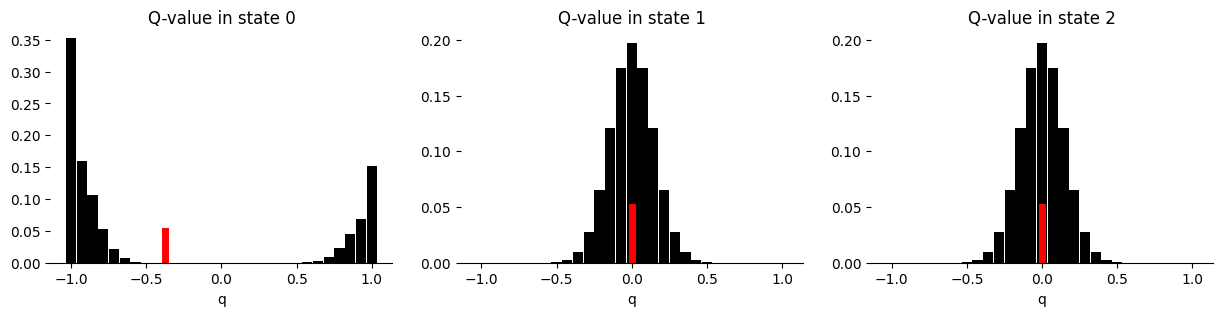

In [ ]:
def plot_Qisaq(a, Qq=mae.Qisaq, gpoints=mae.gridpoints, wdth=mae.gridwidth):
    fig, axes = plt.subplots(1, 3, figsize=(15,3))
    for s, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Qq[0,s,a,:], width=0.95*wdth, color='k')
        mQ = np.dot(gpoints, Qq[0,s,a,:])
        ax.plot([mQ, mQ], [0.0, 0.05], c='red', lw=5)
        ax.set_xlabel("q")
        ax.set_title("Q-value in state "+str(s))
        ax.set_ylim([0, np.max(Qq[0,s,a,:])+0.01])
    

plot_Qisaq(0, Qq=mae.Qisaq(X), gpoints=mae.gridpoints, wdth=mae.gridwidth)

In [ ]:
quantiles = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
qqs = np.zeros((len(quantiles), 1, 3, 2))

In [ ]:
for i, q in enumerate(quantiles):
    mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                     learning_rates=0.1, discount_factors=0, 
                     choice_intensities=4, quantile=q, use_prefactor=False)
    _Qisa = mae._Qisa(X)
    qqs[i, :, :, :] = _Qisa

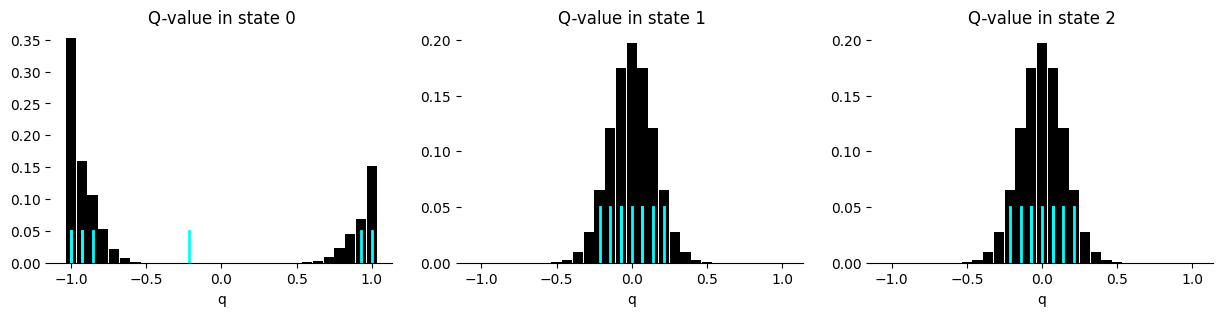

In [ ]:
def plot_Qisaq_w_quantiles(a, Qq=mae.Qisaq, gpoints=mae.gridpoints, wdth=mae.gridwidth):
    fig, axes = plt.subplots(1, 3, figsize=(15,3))
    for s, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Qq[0,s,a,:], width=0.95*wdth, color='k')
        quantiles = qqs[:, 0, s, a]
        ax.plot([quantiles, quantiles], [0.0, 0.05], c='cyan', lw=2)
        ax.set_xlabel("q")
        ax.set_title("Q-value in state "+str(s))
        ax.set_ylim([0, np.max(Qq[0,s,a,:])+0.01])
    

plot_Qisaq_w_quantiles(0, Qq=mae.Qisaq(X), gpoints=mae.gridpoints, wdth=mae.gridwidth)

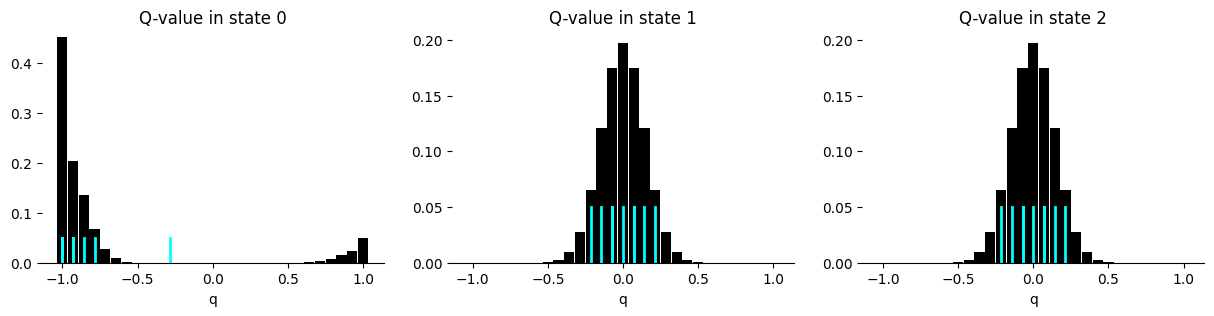

In [ ]:
plot_Qisaq_w_quantiles(1, Qq=mae.Qisaq(X), gpoints=mae.gridpoints, wdth=mae.gridwidth)

In [ ]:
qqs[:, 0, 0, 0]

array([-1.        , -1.        , -1.        , -0.9285714 , -0.9285714 ,
       -0.85714287, -0.21428572,  0.9285714 ,  1.        ])

In [ ]:
qqs[:, 0, 0, 1]

array([-1.        , -1.        , -1.        , -1.        , -0.9285714 ,
       -0.9285714 , -0.85714287, -0.78571427, -0.2857143 ])

In [ ]:
qqs[:, 0, 1, 0]

array([-0.21428572, -0.14285715, -0.07142857, -0.07142857,  0.        ,
        0.07142857,  0.07142857,  0.14285715,  0.21428572])

In [ ]:
qqs[:, 0, 2, 0]

array([-0.21428572, -0.14285715, -0.07142857, -0.07142857,  0.        ,
        0.07142857,  0.07142857,  0.14285715,  0.21428572])

In [ ]:
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA

In [ ]:
# Poor environment
xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.7, 0.3],
               [0.9, 0.1]])
env1s = DistTwoArmedBanditOneState(disttype='discrete', xs=xs, ps=ps)

In [ ]:
quantiles = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
qqs = np.zeros((len(quantiles), 1, 1, 2))

In [ ]:
X = 0.5 * np.ones((1, 1, 2))

In [ ]:
for i, q in enumerate(quantiles):
    mae = qbaseSARSA(env1s, nr_reward_bins=29, discretization_sigma=0.1, 
                     learning_rates=0.1, discount_factors=0, 
                     choice_intensities=4, Rmin=-2, Rmax=2, quantile=q, 
                     use_prefactor=False)
    _Qisa = mae._Qisa(X)
    qqs[i, :, :, :] = _Qisa

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


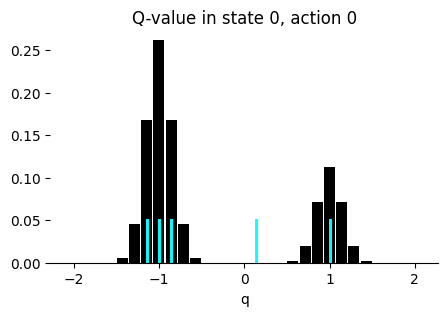

In [ ]:
def plot_Qisaq_w_quantiles(a, Qq=mae.Qisaq, gpoints=mae.gridpoints, wdth=mae.gridwidth):
    fig, ax = plt.subplots(1, 1, figsize=(5,3))
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(gpoints, Qq[0,0,a,:], width=0.9*wdth, color='k')
    quantiles = qqs[:, 0, 0, a]
    ax.plot([quantiles, quantiles], [0.0, 0.05], c='cyan', lw=2)
    ax.set_xlabel("q")
    ax.set_title("Q-value in state 0, action "+str(a))
    ax.set_ylim([0, np.max(Qq[0,0,a,:])+0.01])
    
plot_Qisaq_w_quantiles(0, Qq=mae.Qisaq(X), gpoints=mae.gridpoints, wdth=mae.gridwidth)

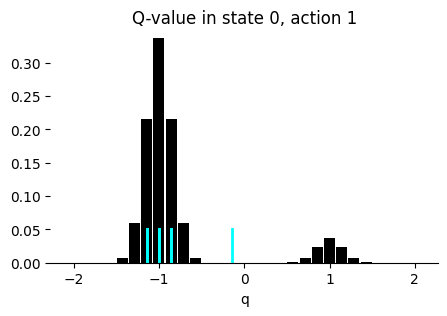

In [ ]:
plot_Qisaq_w_quantiles(1, Qq=mae.Qisaq(X), gpoints=mae.gridpoints, wdth=mae.gridwidth)